# Retrieval tuning and Evaluation

Dev-set only, this notebook is meant to be run often and cheaply, everything
here is local vector search, no generation calls, no cost. The test set stays
untouched until we have a final chosen configuration to report, that happens
in a later notebook.

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import sys
sys.path.append("..")

import pandas as pd
from pathlib import Path

from evaluation import dataset, retrieval_metrics as rm

EVAL_SET_PATH = Path("../data/eval/evalset.json")
SPLIT_PATH = Path("../data/eval/split.json")

### Step 1, load and split

Stratified by question_type and difficulty, 20% dev / 80% test. The split
gets saved once and reloaded after that, so it stays identical across every
future run, this notebook, the final evaluation notebook, and whatever we
build for hybrid retrieval.

In [3]:
if SPLIT_PATH.exists():
    dev, test = dataset.load_split(SPLIT_PATH)
    print("loaded existing split")
else:
    items = dataset.load_eval_set(EVAL_SET_PATH)
    dev, test = dataset.stratified_split(items, dev_fraction=0.2)
    dataset.save_split(dev, test, SPLIT_PATH)
    print("created and saved new split")

print(f"dev: {len(dev)} questions, test: {len(test)} questions")
pd.DataFrame(dev)[["question_type", "difficulty"]].value_counts()

loaded existing split
dev: 20 questions, test: 80 questions


question_type  difficulty
factoid        medium        8
               easy          7
               hard          3
reasoning      hard          2
Name: count, dtype: int64

## `Baseline` system with `Dense` retrieval and `k=5`

### Step 2, baseline retrieval metrics on dev (k=5, current default)

In [4]:
rows = rm.evaluate_retrieval(dev, k=5)
df = pd.DataFrame(rows)

print("overall")
print(df[["hit_rate", "reciprocal_rank", "precision_at_k", "average_precision"]].mean())
print()
print("by question_type")
print(df.groupby("question_type")[["hit_rate", "reciprocal_rank", "precision_at_k", "average_precision"]].mean())
print()
print("by difficulty")
print(df.groupby("difficulty")[["hit_rate", "reciprocal_rank", "precision_at_k", "average_precision"]].mean())

d:\Aanaconda\envs\ukask\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


    loading embedding model, ~2GB, first run downloads it, be patient...


Loading weights: 100%|██████████| 391/391 [00:00<00:00, 23548.28it/s]


    embedding model ready
overall
hit_rate             0.650000
reciprocal_rank      0.464167
precision_at_k       0.160000
average_precision    0.130399
dtype: float64

by question_type
               hit_rate  reciprocal_rank  precision_at_k  average_precision
question_type                                                              
factoid        0.666667         0.460185        0.166667           0.141416
reasoning      0.500000         0.500000        0.100000           0.031250

by difficulty
            hit_rate  reciprocal_rank  precision_at_k  average_precision
difficulty                                                              
easy        0.714286         0.433333        0.171429           0.137302
hard        0.400000         0.400000        0.120000           0.092500
medium      0.750000         0.531250        0.175000           0.148047


### Step 2b, inspect the actual failures

Not just the aggregate numbers, what specifically went wrong, and what got
retrieved instead of the right answer. This is where the real caveats show up.

In [ ]:
rows = rm.evaluate_retrieval(dev, k=5)

misses = [r for r in rows if r["hit_rate"] == 0.0]
print(f"{len(misses)} of {len(rows)} dev questions had zero relevant chunks in the top 5")
print()

for r in misses:
    print(f"Q{r['id']} [{r['question_type']}/{r['difficulty']}]  target: {r['source']}")
    print(f"  {r['question']}")
    print("  retrieved instead:")
    for c in r["retrieved"][:3]:
        meta = c["metadata"]
        similarity = 1 - c["distance"]
        print(f"    sim={similarity:.3f}  article={meta.get('article_numbers')}  {c['text'][:80]}")
    print()

7 of 20 dev questions had zero relevant chunks in the top 5

Q21 [factoid/easy]  target: ماده ۱۹
  حداکثر مرخصی تحصیلی در کارشناسی پیوسته چند نیمسال است؟
  retrieved instead:
    sim=0.709  article=6,7  - 14 C 99 / 12 - 13 D 99 / 10 - 11 F 99 / 9 - 0 توضیح اینکه نمره قبولی برای دانش
    sim=0.701  article=5  . شهریه ثابت تعیین شده مربوط را بپردازد. صدور مرخصی تحصیلی بدون پرداخت شهریه ثاب
    sim=0.685  article=7,8,9,10,11  و برای دانشجویان کارشناسی ارشد پیوسته و دکتری دامپزشکی سه نیمسال می‌باشد ماده 7.

Q48 [factoid/easy]  target: تبصره ۲ ماده ۱۱
  آیا تسهیلات حذف نمره مردودی شامل موارد تقلب می‌شود؟
  retrieved instead:
    sim=0.611  article=20  در ریز نمرات ثبت و در میانگین نیمسال تحصیلی محاسبه می‌شود. درخواست کتبی دانشجو و
    sim=0.604  article=10,11,12  توسط دانشجو به عنوان انصراف از تحصیل بوده و در هر صورت عدم پیگیری دانشجو و عدم ت
    sim=0.568  article=unknown  |تروص رد و دوش لمع|Col 2 |Col 3 |Col 4 |Col 5 |Col 6 | 4 |هدام دننام دیاب ناتسرا

Q45 [factoid/medium]  target: تبصره 

### Step 2c, save these results

In [7]:
from evaluation import results

results.save_results(
    rows,
    "../data/eval/results/retrieval_baseline_k5.json",
    label="baseline_dense_k5",
)

### Step 3, k sweep

A small preview of the tuning workflow, try a few k values, compare on dev.
Widen the range or add other parameters (like the relevance threshold) the
same way once this shape feels right.

In [ ]:
sweep_results = []
for k in [3, 5, 7, 10]:
    rows = rm.evaluate_retrieval(dev, k=k)
    df_k = pd.DataFrame(rows)
    means = df_k[["hit_rate", "reciprocal_rank", "precision_at_k", "average_precision"]].mean()
    sweep_results.append({"k": k, **means.to_dict()})

pd.DataFrame(sweep_results)

,k,hit_rate,reciprocal_rank,precision_at_k,average_precision
0,3,0.55,0.441667,0.233333,0.112899
1,5,0.65,0.464167,0.160000,0.130399
2,7,0.65,0.464167,0.121429,0.131987
3,10,0.65,0.464167,0.090000,0.133653


## Comparing `Dense` and `Hybrid` Retrieval

In [7]:
from backend import retriever

dense_rows = rm.evaluate_retrieval(dev, k=10)
hybrid_rows = rm.evaluate_retrieval(dev, k=10, search_fn=retriever.search_hybrid)

import pandas as pd
dense_df = pd.DataFrame(dense_rows)
hybrid_df = pd.DataFrame(hybrid_rows)

cols = ["hit_rate", "reciprocal_rank", "precision_at_k", "average_precision"]
comparison = pd.DataFrame({"dense": dense_df[cols].mean(), "hybrid": hybrid_df[cols].mean()})
comparison

,dense,hybrid
hit_rate,0.650000,0.750000
reciprocal_rank,0.464167,0.462222
precision_at_k,0.095000,0.115000
average_precision,0.134464,0.117654


## Plots

In [10]:
"""Report plots for the evaluation notebooks. Kept separate from the metric
logic itself, this module only turns already-computed results into figures.
"""

import matplotlib.pyplot as plt
import tiktoken

_encoding = None


def _get_encoding():
    global _encoding
    if _encoding is None:
        # gpt-4o's real tokenizer, so the token counts reflect what the
        # generator actually sees, not an approximation from a different model
        _encoding = tiktoken.encoding_for_model("gpt-4o")
    return _encoding


def count_tokens(text):
    return len(_get_encoding().encode(text))


def sweep_k_with_tokens(questions, k_values, search_fn=None):
    """For each k, runs retrieval metrics AND measures how many context
    tokens that k would actually cost at generation time, summed across the
    retrieved chunks, averaged over the question set."""
    from evaluation import retrieval_metrics as rm

    rows = []
    for k in k_values:
        metric_rows = rm.evaluate_retrieval(questions, k=k, search_fn=search_fn)
        avg_metrics = {
            col: sum(r[col] for r in metric_rows) / len(metric_rows)
            for col in ["hit_rate", "reciprocal_rank", "precision_at_k", "average_precision"]
        }
        avg_tokens = sum(
            sum(count_tokens(c["text"]) for c in r["retrieved"])
            for r in metric_rows
        ) / len(metric_rows)

        rows.append({"k": k, **avg_metrics, "avg_context_tokens": avg_tokens})
    return rows


def plot_confusion_matrix(y_true, y_pred, labels, title="Confusion matrix"):
    """General-purpose, works for the relevance-gate accuracy check below,
    or for the verdict/article_hit cross-tab, or anything else classification-shaped."""
    import numpy as np

    n = len(labels)
    label_index = {label: i for i, label in enumerate(labels)}
    matrix = np.zeros((n, n), dtype=int)
    for actual, predicted in zip(y_true, y_pred):
        matrix[label_index[actual], label_index[predicted]] += 1

    fig, ax = plt.subplots(figsize=(5, 5))
    im = ax.imshow(matrix, cmap="Blues")
    ax.set_xticks(range(n))
    ax.set_yticks(range(n))
    ax.set_xticklabels(labels)
    ax.set_yticklabels(labels)
    ax.set_xlabel("predicted")
    ax.set_ylabel("actual")
    ax.set_title(title)

    threshold = matrix.max() / 2 if matrix.max() > 0 else 0
    for i in range(n):
        for j in range(n):
            color = "white" if matrix[i, j] > threshold else "black"
            ax.text(j, i, str(matrix[i, j]), ha="center", va="center", color=color)

    fig.colorbar(im, ax=ax)
    fig.tight_layout()
    return fig


def evaluate_refusal_accuracy(labeled_queries, k=5):
    """labeled_queries: dict of {question: is_relevant_bool}, like the 30
    relevant/off-topic set built earlier for threshold calibration.
    Runs each through the real pipeline and checks whether the relevance
    gate's answer/refuse decision matches what it should have been, a real
    confusion matrix needs genuine ground truth on both classes, this is
    where that actually exists, the professor's 100 questions don't include
    labeled unanswerable ones."""
    from backend import rag

    y_true, y_pred = [], []
    for question, is_relevant in labeled_queries.items():
        result = rag.answer_question(question, k=k)
        was_answered = len(result["sources"]) > 0
        y_true.append("answer" if is_relevant else "refuse")
        y_pred.append("answer" if was_answered else "refuse")
    return y_true, y_pred


def plot_k_sweep(sweep_rows, title="Retrieval metrics vs k"):
    ks = [r["k"] for r in sweep_rows]
    fig, ax1 = plt.subplots(figsize=(8, 5))

    for metric, marker in [
        ("hit_rate", "o"), ("reciprocal_rank", "s"),
        ("precision_at_k", "^"), ("average_precision", "d"),
    ]:
        ax1.plot(ks, [r[metric] for r in sweep_rows], marker=marker, label=metric)
    ax1.set_xlabel("k")
    ax1.set_ylabel("metric value")
    ax1.set_ylim(0, 1.05)
    ax1.legend(loc="upper left")

    ax2 = ax1.twinx()
    ax2.plot(ks, [r["avg_context_tokens"] for r in sweep_rows],
              color="gray", linestyle="--", marker="x", label="avg context tokens")
    ax2.set_ylabel("avg context tokens sent to generator")
    ax2.legend(loc="upper right")

    plt.title(title)
    plt.xticks(ks)
    fig.tight_layout()
    return fig

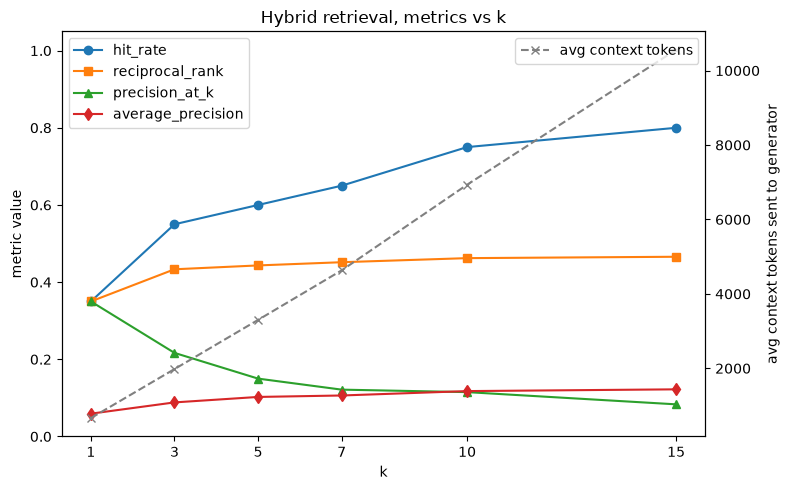

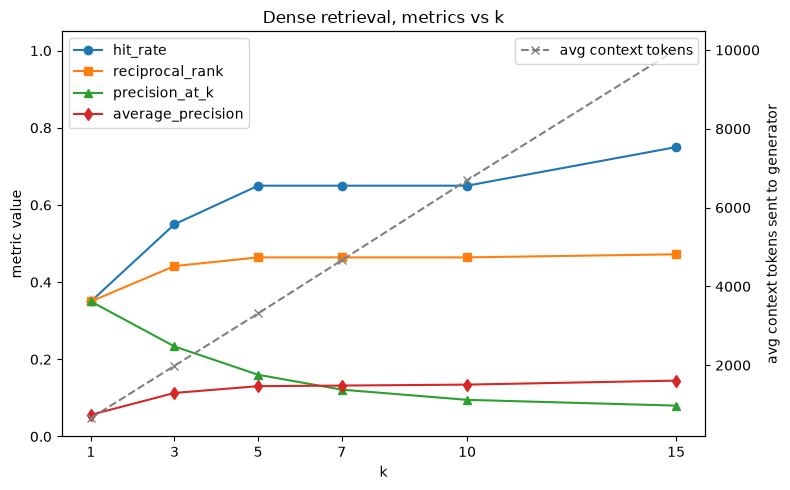

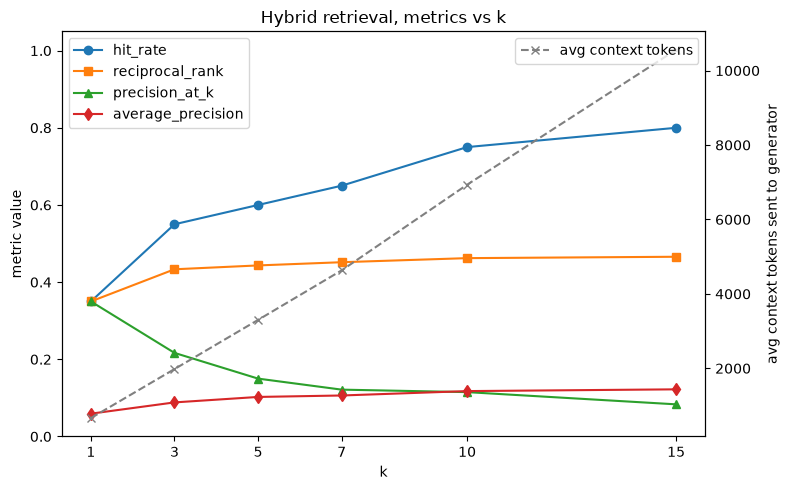

In [ ]:
sweep = sweep_k_with_tokens(dev, k_values=[1, 3, 5, 7, 10, 15])
plot_k_sweep(sweep, title="Dense retrieval, metrics vs k")


from backend import retriever
sweep_hybrid = sweep_k_with_tokens(dev, k_values=[1, 3, 5, 7, 10, 15], search_fn=retriever.search_hybrid)
plot_k_sweep(sweep_hybrid, title="Hybrid retrieval, metrics vs k")